# Supervised Machine Learning Classification Project
## Breast Cancer Wisconsin (Original) Dataset

**Goal:** build and compare five supervised classifiers (KNN, Decision Tree, Random Forest, ANN, SVM) that predict whether a breast tumour is **benign** or **malignant** from nine cytological features, and pick the best model using experimental results only.

**Positive class:** malignant (so *recall* = the share of cancers we actually catch).

**Notebook outline**
1. Task 1 - Dataset exploration
2. Task 2 - Data preprocessing (no data leakage)
3. Task 3 - Exploratory data analysis
4. Task 4 - Model implementation and hyperparameter tuning
5. Task 5 - Model evaluation and comparison
6. Conclusion

Dataset: UCI Machine Learning Repository - *Breast Cancer Wisconsin (Original)*, Dr. William H. Wolberg, University of Wisconsin Hospitals, Madison.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')
COLORS = {'Benign': '#2A9D8F', 'Malignant': '#D6336C'}
plt.rcParams['figure.dpi'] = 100
print('Libraries loaded.')

Libraries loaded.


---
# Task 1: Dataset Exploration

### 1.1 Load the data
The file `breast-cancer-wisconsin.data` has **no header row**, so the column names are taken from the documentation file (`breast-cancer-wisconsin.names`). Missing values are written as `?` in the raw file, so they are read as `NaN`.

In [2]:
columns = ['Sample_code_number', 'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape',
           'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei', 'Bland_Chromatin',
           'Normal_Nucleoli', 'Mitoses', 'Class']

import os
DATA_PATH = 'breast-cancer-wisconsin.data'                       # put the file next to the notebook
if not os.path.exists(DATA_PATH):
    DATA_PATH = '/mnt/user-data/uploads/breast-cancer-wisconsin.data'
df = pd.read_csv(DATA_PATH, header=None, names=columns, na_values='?')
df.head()

,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1.0,3,1,1,2
1,1002945,5,4,4,5,7,10.0,3,2,1,2
2,1015425,3,1,1,1,2,2.0,3,1,1,2
3,1016277,6,8,8,1,3,4.0,3,7,1,2
4,1017023,4,1,1,3,2,1.0,3,1,1,2


### 1.2 Structure, dimensions, column names and data types

In [3]:
print('Shape (rows, columns):', df.shape)
print('\nColumn names:', list(df.columns))
print()
df.info()

Shape (rows, columns): (699, 11)

Column names: ['Sample_code_number', 'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape', 'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Class']

<class 'pandas.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Sample_code_number           699 non-null    int64  
 1   Clump_Thickness              699 non-null    int64  
 2   Uniformity_of_Cell_Size      699 non-null    int64  
 3   Uniformity_of_Cell_Shape     699 non-null    int64  
 4   Marginal_Adhesion            699 non-null    int64  
 5   Single_Epithelial_Cell_Size  699 non-null    int64  
 6   Bare_Nuclei                  683 non-null    float64
 7   Bland_Chromatin              699 non-null    int64  
 8   Normal_Nucleoli              699 non-null    int64

**Observations:** the dataset has 699 rows and 11 columns. Every column is numeric. `Bare_Nuclei` is stored as `float64` (not `int64`) only because it contains `NaN` values, which come from the `?` entries in the raw file.

### 1.3 Feature meanings and target labels (from the documentation)

| # | Column | Meaning (cytology of a fine-needle aspirate) | Values |
|---|---|---|---|
| 1 | `Sample_code_number` | Patient/sample identifier - **not a feature** | ID number |
| 2 | `Clump_Thickness` | Whether cells are in monolayers or multi-layered clumps (cancer cells tend to pile up) | 1-10 |
| 3 | `Uniformity_of_Cell_Size` | How similar the cell sizes are | 1-10 |
| 4 | `Uniformity_of_Cell_Shape` | How similar the cell shapes are | 1-10 |
| 5 | `Marginal_Adhesion` | How strongly cells stick to each other (loss of adhesion is typical of malignancy) | 1-10 |
| 6 | `Single_Epithelial_Cell_Size` | Size of single epithelial cells (enlarged cells can be malignant) | 1-10 |
| 7 | `Bare_Nuclei` | Nuclei not surrounded by cytoplasm | 1-10 |
| 8 | `Bland_Chromatin` | Texture of the nuclear chromatin (coarse = more suspicious) | 1-10 |
| 9 | `Normal_Nucleoli` | Size/visibility of the nucleoli | 1-10 |
| 10 | `Mitoses` | Rate of cell division | 1-10 |
| 11 | `Class` | **Target**: `2` = benign, `4` = malignant | 2 / 4 |

All nine predictive features are ordinal scores from 1 (normal) to 10 (most abnormal).

In [4]:
target = 'Class'
id_col = 'Sample_code_number'
features = [c for c in df.columns if c not in (id_col, target)]
print('Target variable   :', target, '(2 = benign, 4 = malignant)')
print('Identifier column :', id_col, '(will be removed)')
print('Predictive features (%d):' % len(features))
for f in features: print('   -', f)

Target variable   : Class (2 = benign, 4 = malignant)
Identifier column : Sample_code_number (will be removed)
Predictive features (9):
   - Clump_Thickness
   - Uniformity_of_Cell_Size
   - Uniformity_of_Cell_Shape
   - Marginal_Adhesion
   - Single_Epithelial_Cell_Size
   - Bare_Nuclei
   - Bland_Chromatin
   - Normal_Nucleoli
   - Mitoses


### 1.4 Descriptive statistics

In [5]:
df[features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Clump_Thickness,699.0,4.42,2.82,1.0,2.0,4.0,6.0,10.0
Uniformity_of_Cell_Size,699.0,3.13,3.05,1.0,1.0,1.0,5.0,10.0
Uniformity_of_Cell_Shape,699.0,3.21,2.97,1.0,1.0,1.0,5.0,10.0
Marginal_Adhesion,699.0,2.81,2.86,1.0,1.0,1.0,4.0,10.0
Single_Epithelial_Cell_Size,699.0,3.22,2.21,1.0,2.0,2.0,4.0,10.0
Bare_Nuclei,683.0,3.54,3.64,1.0,1.0,1.0,6.0,10.0
Bland_Chromatin,699.0,3.44,2.44,1.0,2.0,3.0,5.0,10.0
Normal_Nucleoli,699.0,2.87,3.05,1.0,1.0,1.0,4.0,10.0
Mitoses,699.0,1.59,1.72,1.0,1.0,1.0,1.0,10.0


### 1.5 Missing values

In [6]:
missing = pd.DataFrame({'Missing count': df.isna().sum(), 'Missing %': (df.isna().mean() * 100).round(2)})
display(missing[missing['Missing count'] > 0])
print('Total missing cells:', int(df.isna().sum().sum()), '| Rows with a missing value:', int(df.isna().any(axis=1).sum()))

,Missing count,Missing %
Bare_Nuclei,16,2.29


Total missing cells: 16 | Rows with a missing value: 16


### 1.6 Duplicate records

In [7]:
n_exact = df.duplicated().sum()
n_feat  = df[features + [target]].duplicated().sum()
n_id    = df[id_col].duplicated().sum()
print('Exact duplicate rows (all 11 columns, including the ID):', n_exact)
print('Rows whose 9 features + class repeat (ignoring the ID)   :', n_feat)
print('Repeated sample code numbers                             :', n_id)
print()
display(df[df.duplicated(keep=False)].sort_values(id_col))

Exact duplicate rows (all 11 columns, including the ID): 8
Rows whose 9 features + class repeat (ignoring the ID)   : 236
Repeated sample code numbers                             : 54



,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
272,320675,3,3,5,2,3,10.0,7,1,1,4
267,320675,3,3,5,2,3,10.0,7,1,1,4
684,466906,1,1,1,1,2,1.0,1,1,1,2
683,466906,1,1,1,1,2,1.0,1,1,1,2
314,704097,1,1,1,1,1,1.0,2,1,1,2
338,704097,1,1,1,1,1,1.0,2,1,1,2
42,1100524,6,10,10,2,8,10.0,7,3,3,4
253,1100524,6,10,10,2,8,10.0,7,3,3,4
62,1116116,9,10,10,1,10,8.0,3,3,1,4
254,1116116,9,10,10,1,10,8.0,3,3,1,4


**Observations:** there are 8 *exact* duplicate rows (same ID and same measurements), which are data-entry repeats of the same sample. Many more rows share the same nine feature values but have **different** sample IDs - with only 10 possible scores per feature that is expected and they are different patients, so they are not removed (a sensitivity check in Task 5 tests this decision).

### 1.7 Class distribution

In [8]:
class_counts = df[target].map({2: 'Benign', 4: 'Malignant'}).value_counts()
display(pd.DataFrame({'Count': class_counts, 'Percent': (class_counts / len(df) * 100).round(1)}))

,Count,Percent
Class,,
Benign,458,65.5
Malignant,241,34.5


**Observations:** 458 benign (65.5%) vs 241 malignant (34.5%), matching the documentation. The classes are moderately imbalanced (about 2:1), so accuracy alone is not enough - precision, recall, F1 and ROC-AUC are reported as well, and the train/test split is stratified.

---
# Task 2: Data Preprocessing

Order of operations (designed to avoid data leakage):
1. Encode the target (malignant = 1, positive class).
2. Remove exact duplicate records, then drop the ID column.
3. **Split 80:20 (stratified) first.**
4. Fit the imputer and the scaler on the **training set only**, then apply them to the test set.
5. During tuning, the imputer and scaler live inside a `Pipeline`, so they are re-fitted on the training folds of every cross-validation split.

### 2.1 Encode the target

In [9]:
data = df.copy()
data['Diagnosis'] = data[target].map({2: 0, 4: 1})      # 0 = benign, 1 = malignant (positive class)
print(data[[target, 'Diagnosis']].value_counts().rename('count'))

Class  Diagnosis
2      0            458
4      1            241
Name: count, dtype: int64


### 2.2 Duplicates and irrelevant features

In [10]:
before = len(data)
data = data.drop_duplicates()                       # exact duplicates (ID included) = repeated entries of the same sample
print(f'Rows before: {before} | exact duplicates removed: {before - len(data)} | rows after: {len(data)}')

data = data.drop(columns=[id_col, target])          # identifier carries no medical information; Class replaced by Diagnosis
print('Columns kept:', list(data.columns))
print('\nClass balance after cleaning:')
print(data['Diagnosis'].value_counts().rename({0: 'Benign', 1: 'Malignant'}))

Rows before: 699 | exact duplicates removed: 8 | rows after: 691
Columns kept: ['Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape', 'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei', 'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses', 'Diagnosis']

Class balance after cleaning:
Diagnosis
Benign       453
Malignant    238
Name: count, dtype: int64


### 2.3 Train / test split (80:20)
`stratify=y` keeps the benign/malignant ratio the same in both sets. The test set is locked away until the final evaluation.

In [11]:
X = data[features]
y = data['Diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print('Training set:', X_train.shape, '| Test set:', X_test.shape)
print('\nMalignant share  - train: %.1f%% | test: %.1f%%' % (y_train.mean() * 100, y_test.mean() * 100))
print('Missing values   - train:', int(X_train.isna().sum().sum()), '| test:', int(X_test.isna().sum().sum()))

Training set: (552, 9) | Test set: (139, 9)

Malignant share  - train: 34.4% | test: 34.5%
Missing values   - train: 14 | test: 2


### 2.4 Missing values: median imputation (fitted on the training set only)
Only `Bare_Nuclei` has missing values. The feature is an ordinal score that is strongly right-skewed (most values are 1), so the **median** is a more sensible replacement than the mean. The median is learned from `X_train` only and then applied to both sets.

In [12]:
imputer = SimpleImputer(strategy='median')
imputer.fit(X_train)                                    # learned from training data only

X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=features, index=X_train.index)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=features, index=X_test.index)

print('Median used for Bare_Nuclei (from training set):', imputer.statistics_[features.index('Bare_Nuclei')])
print('Missing after imputation - train:', int(X_train_imp.isna().sum().sum()), '| test:', int(X_test_imp.isna().sum().sum()))

Median used for Bare_Nuclei (from training set): 1.0
Missing after imputation - train: 0 | test: 0


### 2.5 Standardization (fitted on the training set only)
KNN, SVM and the neural network are sensitive to feature scale, so features are standardized to mean 0 and standard deviation 1 (`z = (x - mean) / std`). The mean and std come from the training set only; the test set is transformed with those same values.

In [13]:
scaler = StandardScaler()
scaler.fit(X_train_imp)

X_train_scaled = pd.DataFrame(scaler.transform(X_train_imp), columns=features, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test_imp),  columns=features, index=X_test.index)

summary = pd.DataFrame({'Train mean': X_train_scaled.mean(), 'Train std': X_train_scaled.std(ddof=0),
                        'Test mean': X_test_scaled.mean(),   'Test std': X_test_scaled.std(ddof=0)}).round(3)
summary

,Train mean,Train std,Test mean,Test std
Clump_Thickness,-0.0,1.0,-0.062,1.032
Uniformity_of_Cell_Size,0.0,1.0,-0.018,0.979
Uniformity_of_Cell_Shape,-0.0,1.0,-0.039,0.984
Marginal_Adhesion,0.0,1.0,0.064,0.997
Single_Epithelial_Cell_Size,-0.0,1.0,0.074,1.113
Bare_Nuclei,0.0,1.0,0.011,1.012
Bland_Chromatin,-0.0,1.0,0.077,1.124
Normal_Nucleoli,0.0,1.0,-0.093,0.968
Mitoses,0.0,1.0,-0.093,0.821


**Check:** the training features have mean 0 and std 1 by construction, while the test set has values close to (but not exactly) 0 and 1. That small difference is the sign that the scaler was *not* refitted on the test data, i.e. there is no leakage.

---
# Task 3: Exploratory Data Analysis (EDA)

To respect the no-leakage rule, the EDA of distributions, outliers and correlations uses the **training set only**. The missing-value chart uses the raw data (it describes data quality before cleaning) and the standardization plots compare the training set before and after scaling.

### 3.1 Histograms: feature distributions

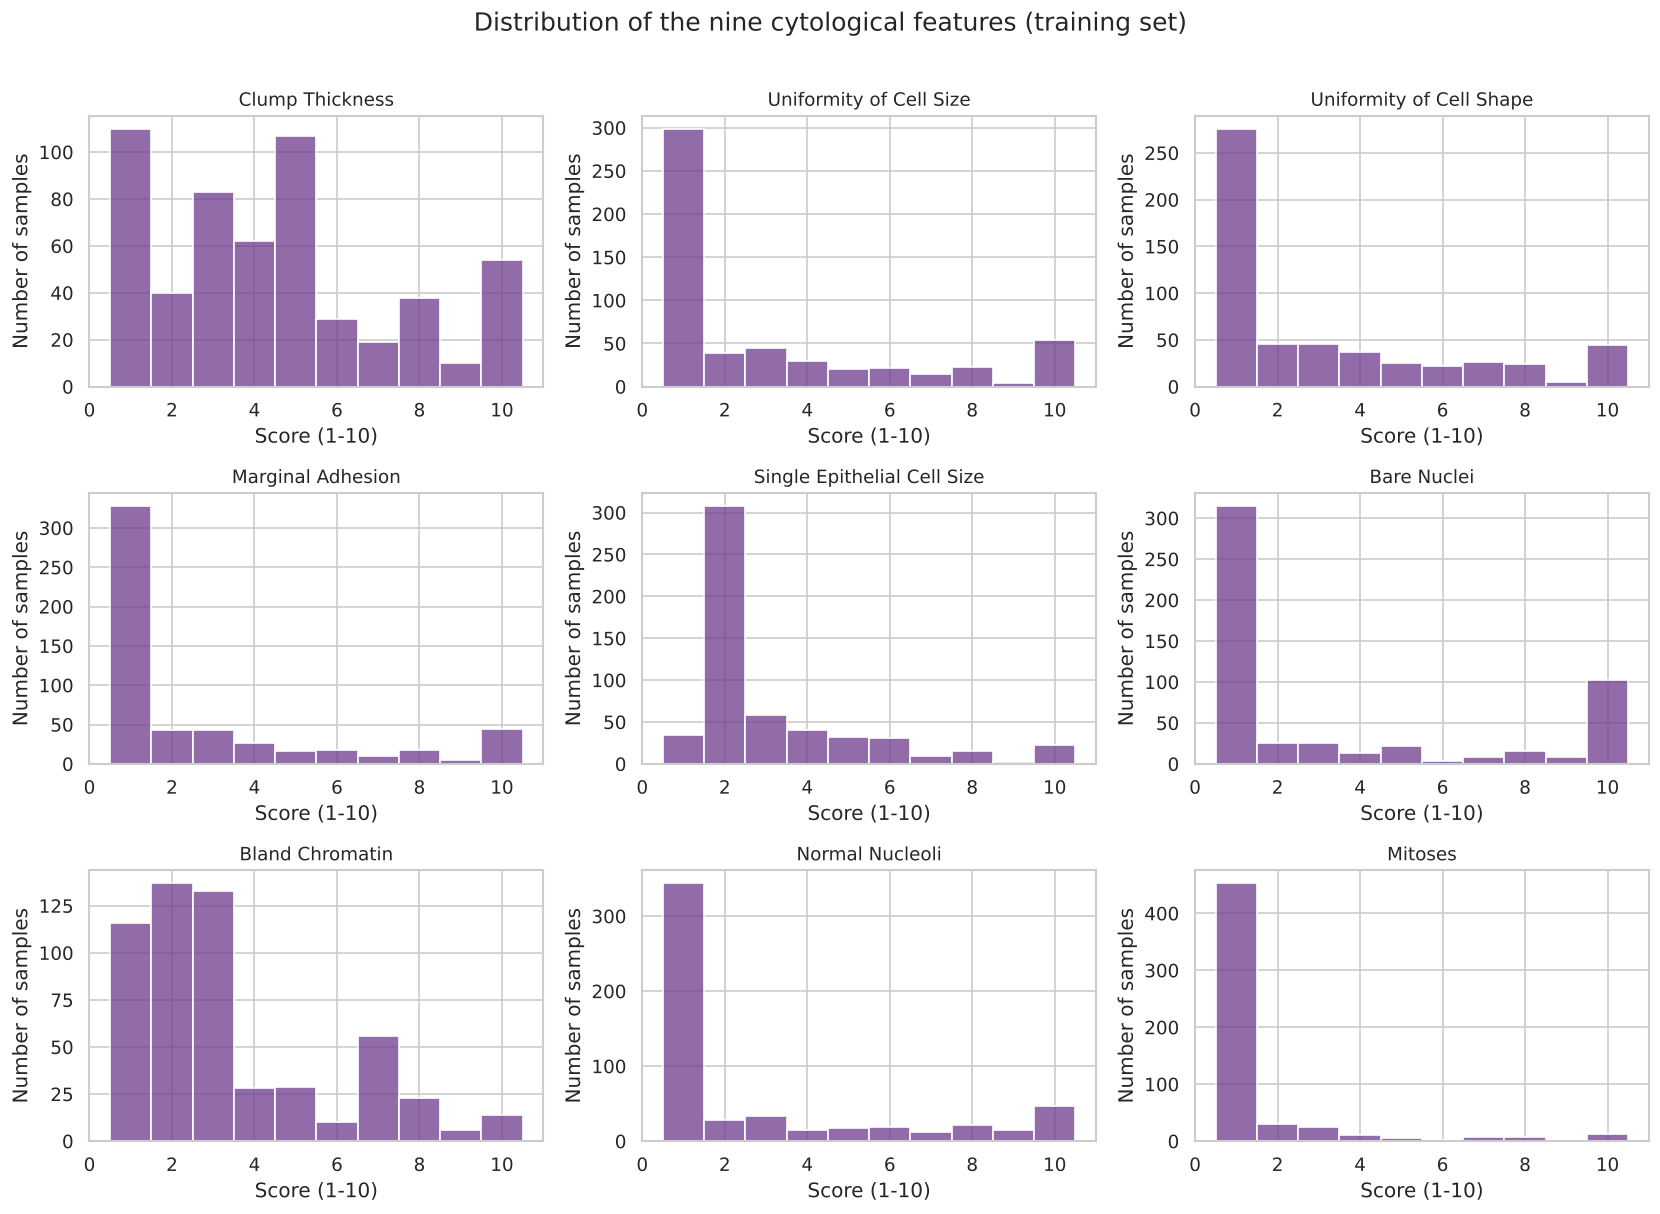

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(X_train[col].dropna(), bins=10, discrete=True, color='#6D3B8C', edgecolor='white', ax=ax)
    ax.set_title(col.replace('_', ' '), fontsize=11)
    ax.set_xlabel('Score (1-10)')
    ax.set_ylabel('Number of samples')
fig.suptitle('Distribution of the nine cytological features (training set)', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

**Interpretation:** most features are strongly **right-skewed**: the bulk of samples score 1 or 2 (normal-looking cells) with a long tail towards 10. `Mitoses` is the extreme case (almost everything is 1), while `Clump Thickness` and `Bland Chromatin` are more spread out. Bare Nuclei and the uniformity features show a second bump at 10, which comes from the malignant cases. None of the features is normally distributed, which is a reason to prefer the median over the mean for imputation.

### 3.2 Count plot: target class distribution

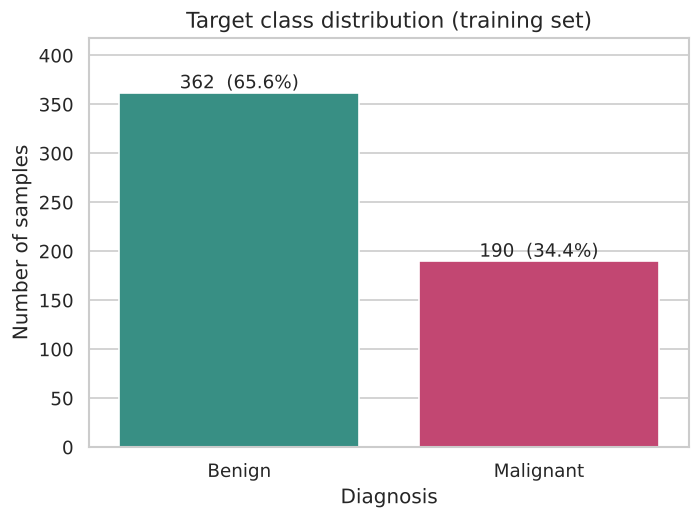

In [15]:
plot_df = y_train.map({0: 'Benign', 1: 'Malignant'}).to_frame('Diagnosis')
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.countplot(data=plot_df, x='Diagnosis', order=['Benign', 'Malignant'], palette=COLORS, ax=ax)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}  ({p.get_height() / len(plot_df) * 100:.1f}%)',
                (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom', fontsize=11)
ax.set_title('Target class distribution (training set)', fontsize=13)
ax.set_xlabel('Diagnosis')
ax.set_ylabel('Number of samples')
ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
plt.tight_layout()
plt.show()

**Interpretation:** the training set keeps the original class ratio (about 66% benign vs 34% malignant) thanks to stratification. The imbalance is mild, so no resampling is needed, but accuracy alone would be a weak yardstick; recall and F1 for the malignant class are tracked as well.

### 3.3 Boxplots: feature distributions by class and potential outliers

,IQR outliers,% of training rows
Clump_Thickness,0,0.0
Uniformity_of_Cell_Size,0,0.0
Uniformity_of_Cell_Shape,0,0.0
Marginal_Adhesion,77,13.9
Single_Epithelial_Cell_Size,39,7.1
Bare_Nuclei,0,0.0
Bland_Chromatin,43,7.8
Normal_Nucleoli,62,11.2
Mitoses,99,17.9


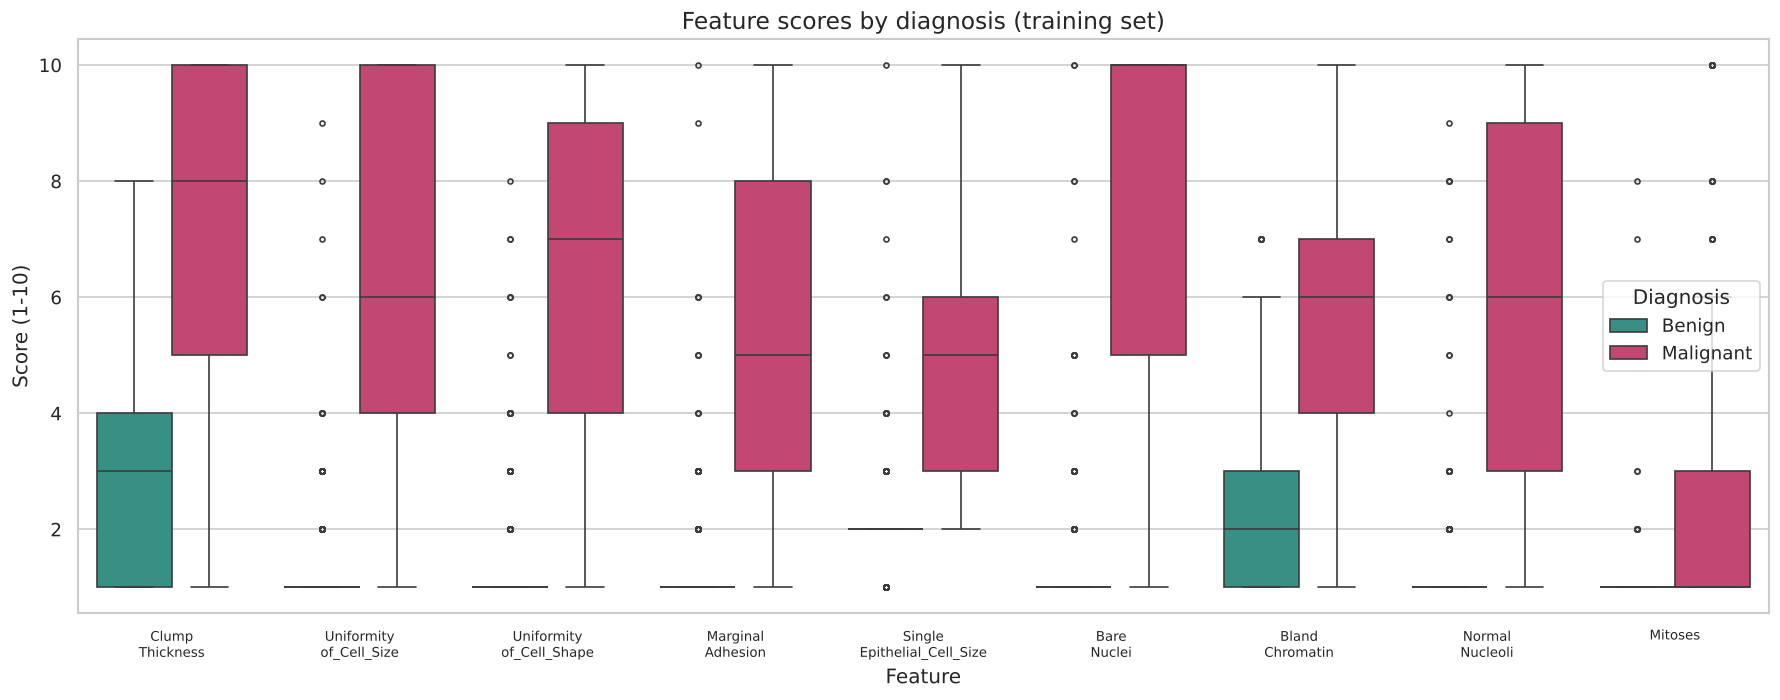

In [16]:
long = X_train.copy()
long['Diagnosis'] = y_train.map({0: 'Benign', 1: 'Malignant'})
long = long.melt(id_vars='Diagnosis', var_name='Feature', value_name='Score')
long['Feature'] = long['Feature'].str.replace('_', '\n', n=1)

fig, ax = plt.subplots(figsize=(15, 6))
sns.boxplot(data=long, x='Feature', y='Score', hue='Diagnosis', palette=COLORS, ax=ax, fliersize=3)
ax.set_title('Feature scores by diagnosis (training set)', fontsize=14)
ax.set_xlabel('Feature')
ax.set_ylabel('Score (1-10)')
ax.tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.show()

# number of IQR outliers per feature
q1, q3 = X_train.quantile(0.25), X_train.quantile(0.75)
iqr = q3 - q1
outliers = ((X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)).sum()
display(pd.DataFrame({'IQR outliers': outliers, '% of training rows': (outliers / len(X_train) * 100).round(1)}))

**Interpretation:** malignant tumours (pink) score clearly higher than benign ones (teal) on almost every feature. The medians differ most for `Bare Nuclei` (1 vs 10), `Uniformity of Cell Shape` (1 vs 7), `Uniformity of Cell Size` (1 vs 6) and `Clump Thickness` (3 vs 8). `Mitoses` barely separates the classes (median 1 in both), so it is expected to be the weakest predictor. The IQR rule flags many "outliers" in `Mitoses` (17.9%), `Marginal Adhesion` (13.9%) and `Normal Nucleoli` (11.2%), but they are valid scores on a 1-10 scale and mostly come from malignant samples, i.e. they carry the signal. They were therefore **kept**.

### 3.4 Correlation heatmap

Correlation with the diagnosis (sorted):
Bare_Nuclei                    0.826
Uniformity_of_Cell_Shape       0.815
Uniformity_of_Cell_Size        0.810
Bland_Chromatin                0.741
Normal_Nucleoli                0.729
Clump_Thickness                0.714
Marginal_Adhesion              0.692
Single_Epithelial_Cell_Size    0.678
Mitoses                        0.428
Name: Diagnosis (malignant=1), dtype: float64


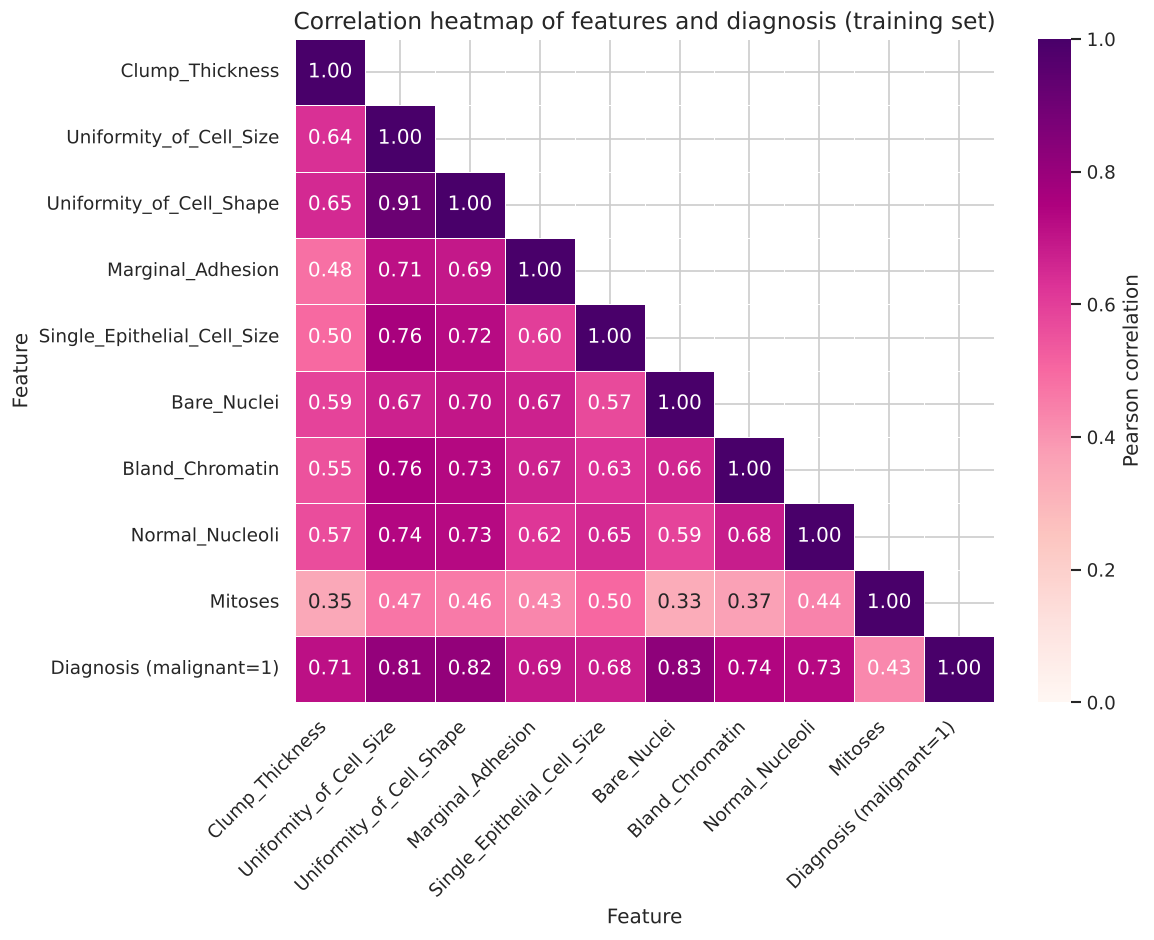

In [17]:
corr_df = X_train.copy()
corr_df['Diagnosis (malignant=1)'] = y_train
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdPu', vmin=0, vmax=1, linewidths=0.5, cbar_kws={'label': 'Pearson correlation'}, ax=ax)
ax.set_title('Correlation heatmap of features and diagnosis (training set)', fontsize=14)
ax.set_xlabel('Feature')
ax.set_ylabel('Feature')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print('Correlation with the diagnosis (sorted):')
print(corr['Diagnosis (malignant=1)'].drop('Diagnosis (malignant=1)').sort_values(ascending=False).round(3))

**Interpretation:** all features correlate positively with the diagnosis. The strongest are `Bare Nuclei` (0.83), `Uniformity of Cell Shape` (0.82) and `Uniformity of Cell Size` (0.81); `Mitoses` is the weakest (0.43). Cell size and cell shape are almost redundant with each other (r = 0.91), so there is some multicollinearity. This is not a problem for trees/forests, SVM or the ANN, and the scores still give a small, easy-to-interpret feature set, so no feature was dropped.

### 3.5 Missing values (raw data)

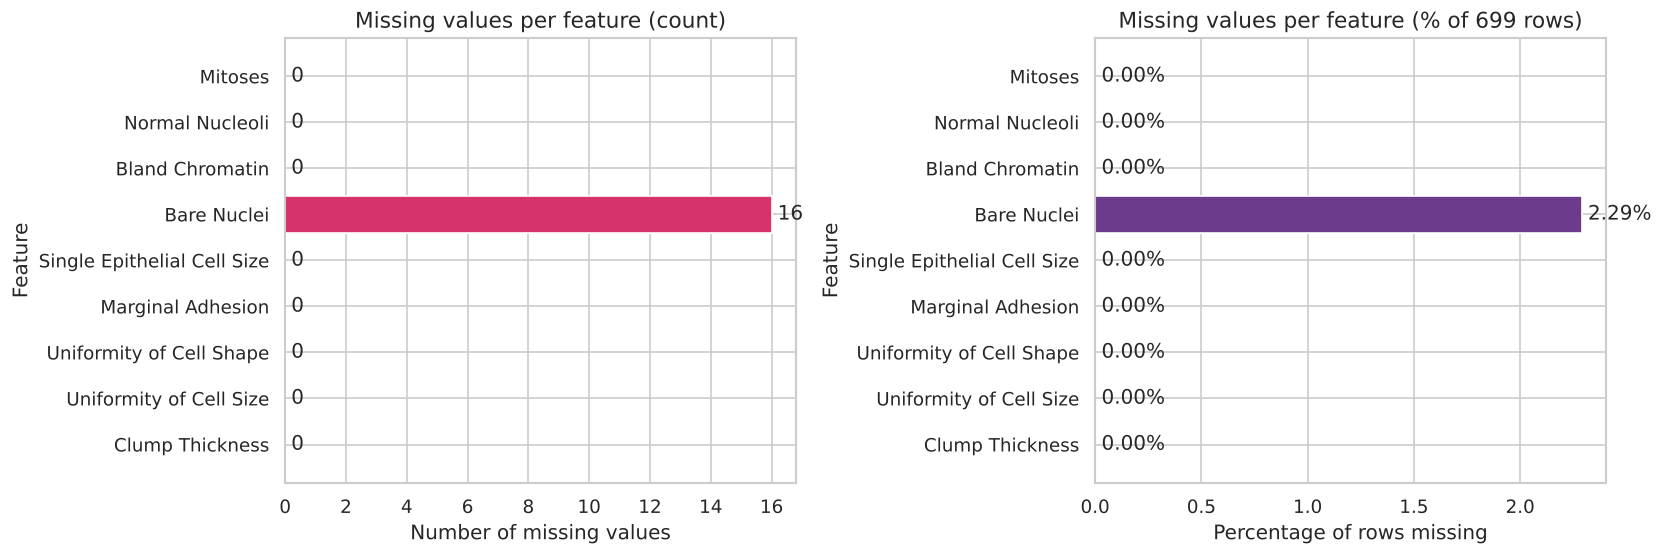

In [18]:
miss = df[features].isna().sum()
miss_pct = miss / len(df) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].barh(miss.index.str.replace('_', ' '), miss.values, color='#D6336C')
axes[0].set_title('Missing values per feature (count)', fontsize=13)
axes[0].set_xlabel('Number of missing values')
axes[0].set_ylabel('Feature')
for i, v in enumerate(miss.values):
    axes[0].text(v + 0.2, i, str(int(v)), va='center')

axes[1].barh(miss_pct.index.str.replace('_', ' '), miss_pct.values, color='#6D3B8C')
axes[1].set_title('Missing values per feature (% of 699 rows)', fontsize=13)
axes[1].set_xlabel('Percentage of rows missing')
axes[1].set_ylabel('Feature')
for i, v in enumerate(miss_pct.values):
    axes[1].text(v + 0.03, i, f'{v:.2f}%', va='center')
plt.tight_layout()
plt.show()

**Interpretation:** only one feature is affected: `Bare Nuclei` has 16 missing values (2.29% of the rows); the other eight features are complete. Because the share is so small, imputing is better than deleting rows, and median imputation is used (inside the pipeline, fitted on the training folds only).

### 3.6 Before-and-after standardization

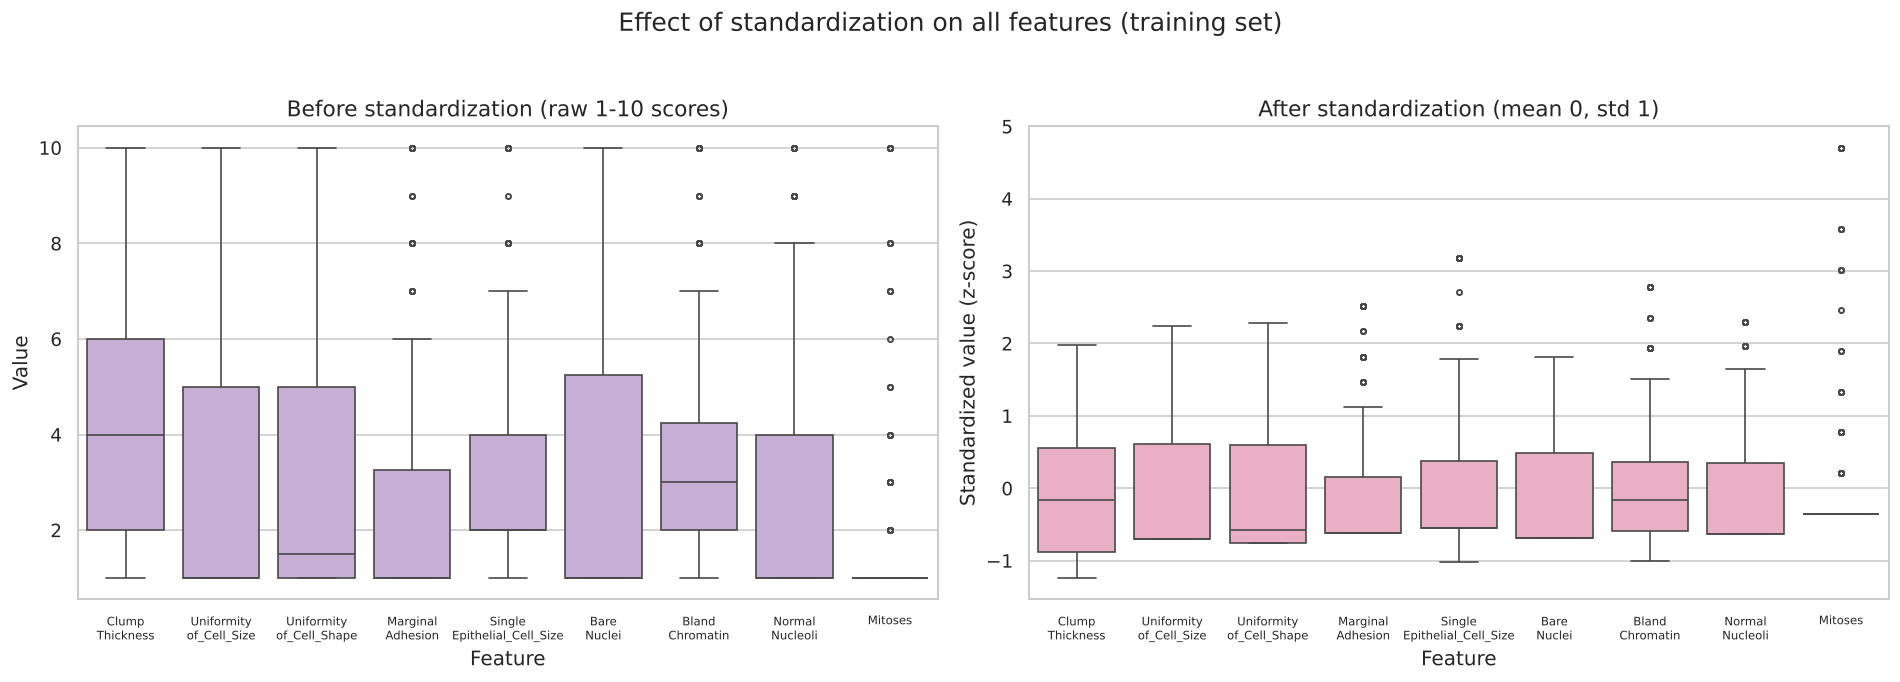

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=False)
sns.boxplot(data=X_train_imp.rename(columns=lambda c: c.replace('_', '\n', 1)), ax=axes[0], color='#C9A7DB', fliersize=3)
axes[0].set_title('Before standardization (raw 1-10 scores)', fontsize=13)
axes[0].set_xlabel('Feature'); axes[0].set_ylabel('Value')
sns.boxplot(data=X_train_scaled.rename(columns=lambda c: c.replace('_', '\n', 1)), ax=axes[1], color='#F2A7C3', fliersize=3)
axes[1].set_title('After standardization (mean 0, std 1)', fontsize=13)
axes[1].set_xlabel('Feature'); axes[1].set_ylabel('Standardized value (z-score)')
for ax in axes: ax.tick_params(axis='x', labelsize=7)
fig.suptitle('Effect of standardization on all features (training set)', fontsize=15, y=1.03)
plt.tight_layout()
plt.show()

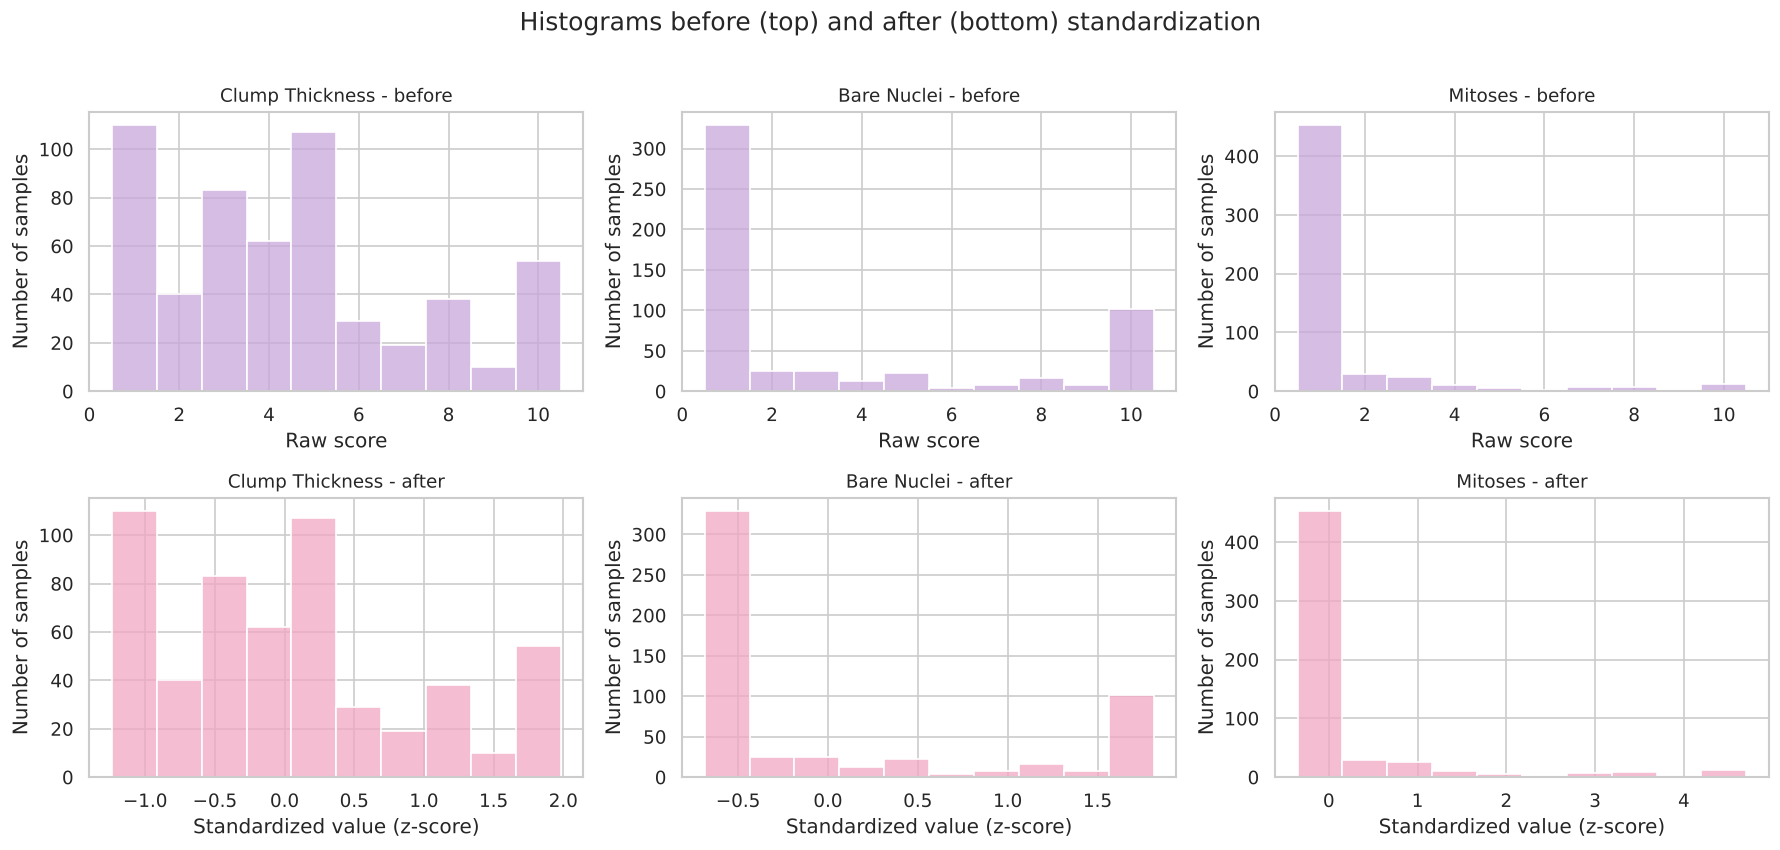

In [20]:
show = ['Clump_Thickness', 'Bare_Nuclei', 'Mitoses']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, col in enumerate(show):
    sns.histplot(X_train_imp[col], bins=10, discrete=True, color='#C9A7DB', edgecolor='white', ax=axes[0, j])
    axes[0, j].set_title(f'{col.replace("_", " ")} - before', fontsize=11)
    axes[0, j].set_xlabel('Raw score'); axes[0, j].set_ylabel('Number of samples')
    sns.histplot(X_train_scaled[col], bins=10, color='#F2A7C3', edgecolor='white', ax=axes[1, j])
    axes[1, j].set_title(f'{col.replace("_", " ")} - after', fontsize=11)
    axes[1, j].set_xlabel('Standardized value (z-score)'); axes[1, j].set_ylabel('Number of samples')
fig.suptitle('Histograms before (top) and after (bottom) standardization', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

**Interpretation:** the raw features all live on the same 1-10 scale but have different means and spreads (for example `Mitoses` is concentrated near 1 while `Clump Thickness` is spread out). After standardization every feature is centred at 0 with unit variance, so distance-based models (KNN, SVM) and the gradient-trained ANN are not dominated by features with larger variance. The **shape** of each distribution does not change, only its location and scale.

---
# Task 4: Model Implementation and Hyperparameter Tuning

**Method.** Each model is wrapped in a `Pipeline` (median imputer -> standard scaler -> classifier) and tuned with `GridSearchCV` using **stratified 5-fold cross-validation on the training set only**. Because the preprocessing is inside the pipeline, it is refitted on the training part of every fold, so the validation fold never influences it. The test set is not touched in this task.

**Tuning metric:** F1-score of the malignant class (a balance between missing cancers and raising false alarms).

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(clf):
    return Pipeline([('imputer', SimpleImputer(strategy='median')),
                     ('scaler', StandardScaler()),
                     ('clf', clf)])

search_space = {
    'KNN': (KNeighborsClassifier(), {
        'clf__n_neighbors': [3, 5, 7, 9, 11, 13, 15],
        'clf__weights': ['uniform', 'distance'],
        'clf__metric': ['euclidean', 'manhattan']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        'clf__criterion': ['gini', 'entropy'],
        'clf__max_depth': [3, 4, 5, 6, 8, None],
        'clf__min_samples_split': [2, 5, 10],
        'clf__min_samples_leaf': [1, 2, 4]}),
    'Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE), {
        'clf__n_estimators': [100, 200, 400],
        'clf__max_depth': [None, 5, 10],
        'clf__max_features': ['sqrt', 'log2'],
        'clf__min_samples_leaf': [1, 2, 4]}),
    'ANN (MLP)': (MLPClassifier(max_iter=2000, random_state=RANDOM_STATE), {
        'clf__hidden_layer_sizes': [(8,), (16,), (32,), (16, 8)],
        'clf__activation': ['relu', 'tanh'],
        'clf__alpha': [1e-4, 1e-3, 1e-2, 1e-1],
        'clf__learning_rate_init': [1e-3, 1e-2]}),
    'SVM': (SVC(random_state=RANDOM_STATE), {
        'clf__kernel': ['rbf', 'linear'],
        'clf__C': [0.1, 1, 10, 100],
        'clf__gamma': ['scale', 0.01, 0.1, 1]}),
}
print({k: int(np.prod([len(v) for v in g.values()])) for k, (_, g) in search_space.items()}, '<- parameter combinations per model (x 5 folds)')

{'KNN': 28, 'Decision Tree': 108, 'Random Forest': 54, 'ANN (MLP)': 64, 'SVM': 32} <- parameter combinations per model (x 5 folds)


In [22]:
searches = {}
tuning_rows = []
for name, (clf, grid) in search_space.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clf), grid, scoring='f1', cv=cv, n_jobs=1, refit=True)
    gs.fit(X_train, y_train)                         # raw training data: preprocessing happens inside each fold
    searches[name] = gs
    best = {k.replace('clf__', ''): v for k, v in gs.best_params_.items()}
    tuning_rows.append({'Model': name, 'Best CV F1': round(gs.best_score_, 4), 'Best hyperparameters': best,
                        'Tuning time (s)': round(time.time() - t0, 1)})
    print(f'{name:14s} best CV F1 = {gs.best_score_:.4f}  |  {best}')

tuning_df = pd.DataFrame(tuning_rows).set_index('Model')

KNN            best CV F1 = 0.9555  |  {'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'uniform'}
Decision Tree  best CV F1 = 0.9297  |  {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 2, 'min_samples_split': 2}
Random Forest  best CV F1 = 0.9537  |  {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 400}
ANN (MLP)      best CV F1 = 0.9559  |  {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (8,), 'learning_rate_init': 0.001}
SVM            best CV F1 = 0.9503  |  {'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}


In [23]:
pd.set_option('display.max_colwidth', 200)
tuning_df

,Best CV F1,Best hyperparameters,Tuning time (s)
Model,,,
KNN,0.9555,"{'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'uniform'}",1.3
Decision Tree,0.9297,"{'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 2, 'min_samples_split': 2}",4.6
Random Forest,0.9537,"{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 400}",72.4
ANN (MLP),0.9559,"{'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (8,), 'learning_rate_init': 0.001}",66.9
SVM,0.9503,"{'C': 0.1, 'gamma': 'scale', 'kernel': 'linear'}",2.1


**Notes:** the best cross-validated F1 values are very close for KNN, Random Forest, ANN and SVM (0.950 - 0.956), while the Decision Tree is lower (0.930). The best SVM uses a *linear* kernel with a small `C`, which suggests the two classes are almost linearly separable in this feature space. The best ANN is a small network (one hidden layer of 8 ReLU units), a sign that a large network is not necessary for this data.

### The five algorithms in brief
- **K-Nearest Neighbors (KNN):** classifies a sample by a vote among its *k* closest training samples. Needs scaled features; tuned: *k*, vote weighting, distance metric.
- **Decision Tree (DT):** learns a hierarchy of if/else questions on the features. Easy to explain but unstable and prone to overfitting; tuned: criterion, depth, minimum samples per split/leaf.
- **Random Forest (RF):** many decision trees trained on random samples/features whose votes are averaged, which reduces variance; tuned: number of trees, depth, features per split, leaf size.
- **Artificial Neural Network (ANN / MLP):** layers of weighted units with non-linear activations trained by gradient descent; tuned: architecture, activation, L2 penalty `alpha`, learning rate.
- **Support Vector Machine (SVM):** finds the maximum-margin boundary, optionally in a kernel-induced space (RBF); tuned: kernel, `C`, `gamma`.

---
# Task 5: Model Evaluation

### 5.1 Metrics used (malignant = positive class)
With TP = malignant correctly detected, TN = benign correctly detected, FP = benign wrongly flagged as malignant, FN = malignant missed:

| Metric | Formula | Meaning in this problem |
|---|---|---|
| **Accuracy** | (TP+TN) / all | Share of all patients classified correctly. Can look good on imbalanced data. |
| **Precision** | TP / (TP+FP) | When the model says "malignant", how often is it right? Low precision = unnecessary biopsies and anxiety. |
| **Recall (sensitivity)** | TP / (TP+FN) | Share of real cancers that are caught. Low recall = missed cancers, the most dangerous error. |
| **F1-score** | 2PR / (P+R) | Harmonic mean of precision and recall. |
| **ROC-AUC** | area under TPR vs FPR | Ability to rank malignant above benign at *every* threshold (1.0 = perfect, 0.5 = random). |
| **Confusion matrix** | 2x2 counts | Shows exactly which errors (FP vs FN) each model makes. |

Every model below is the best estimator found in Task 4, evaluated **once** on the untouched test set.

In [24]:
def get_scores(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

rows, preds, cms, scores = [], {}, {}, {}
for name, gs in searches.items():
    model = gs.best_estimator_
    y_pred = model.predict(X_test)
    s = get_scores(model, X_test)
    preds[name], scores[name] = y_pred, s
    cms[name] = confusion_matrix(y_test, y_pred)
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, y_pred),
                 'Precision': precision_score(y_test, y_pred),
                 'Recall': recall_score(y_test, y_pred),
                 'F1-score': f1_score(y_test, y_pred),
                 'ROC-AUC': roc_auc_score(y_test, s),
                 'CV F1 (train)': gs.best_score_})

results = pd.DataFrame(rows).set_index('Model')
results

,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV F1 (train)
Model,,,,,,
KNN,0.964029,0.977778,0.916667,0.946237,0.982257,0.955490
Decision Tree,0.928058,0.895833,0.895833,0.895833,0.975504,0.929701
Random Forest,0.971223,0.958333,0.958333,0.958333,0.994048,0.953747
ANN (MLP),0.971223,0.958333,0.958333,0.958333,0.996108,0.955895
SVM,0.964029,0.957447,0.937500,0.947368,0.996795,0.950291


### 5.2 Comparison table of all models (test set)

In [25]:
comparison = results.sort_values(['F1-score', 'Recall', 'ROC-AUC'], ascending=False).round(4)
display(comparison.style.format('{:.4f}').highlight_max(color='#F9C6D8'))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV F1 (train)
Model,,,,,,
ANN (MLP),0.9712,0.9583,0.9583,0.9583,0.9961,0.9559
Random Forest,0.9712,0.9583,0.9583,0.9583,0.9940,0.9537
SVM,0.9640,0.9574,0.9375,0.9474,0.9968,0.9503
KNN,0.9640,0.9778,0.9167,0.9462,0.9823,0.9555
Decision Tree,0.9281,0.8958,0.8958,0.8958,0.9755,0.9297


### 5.3 Confusion matrices

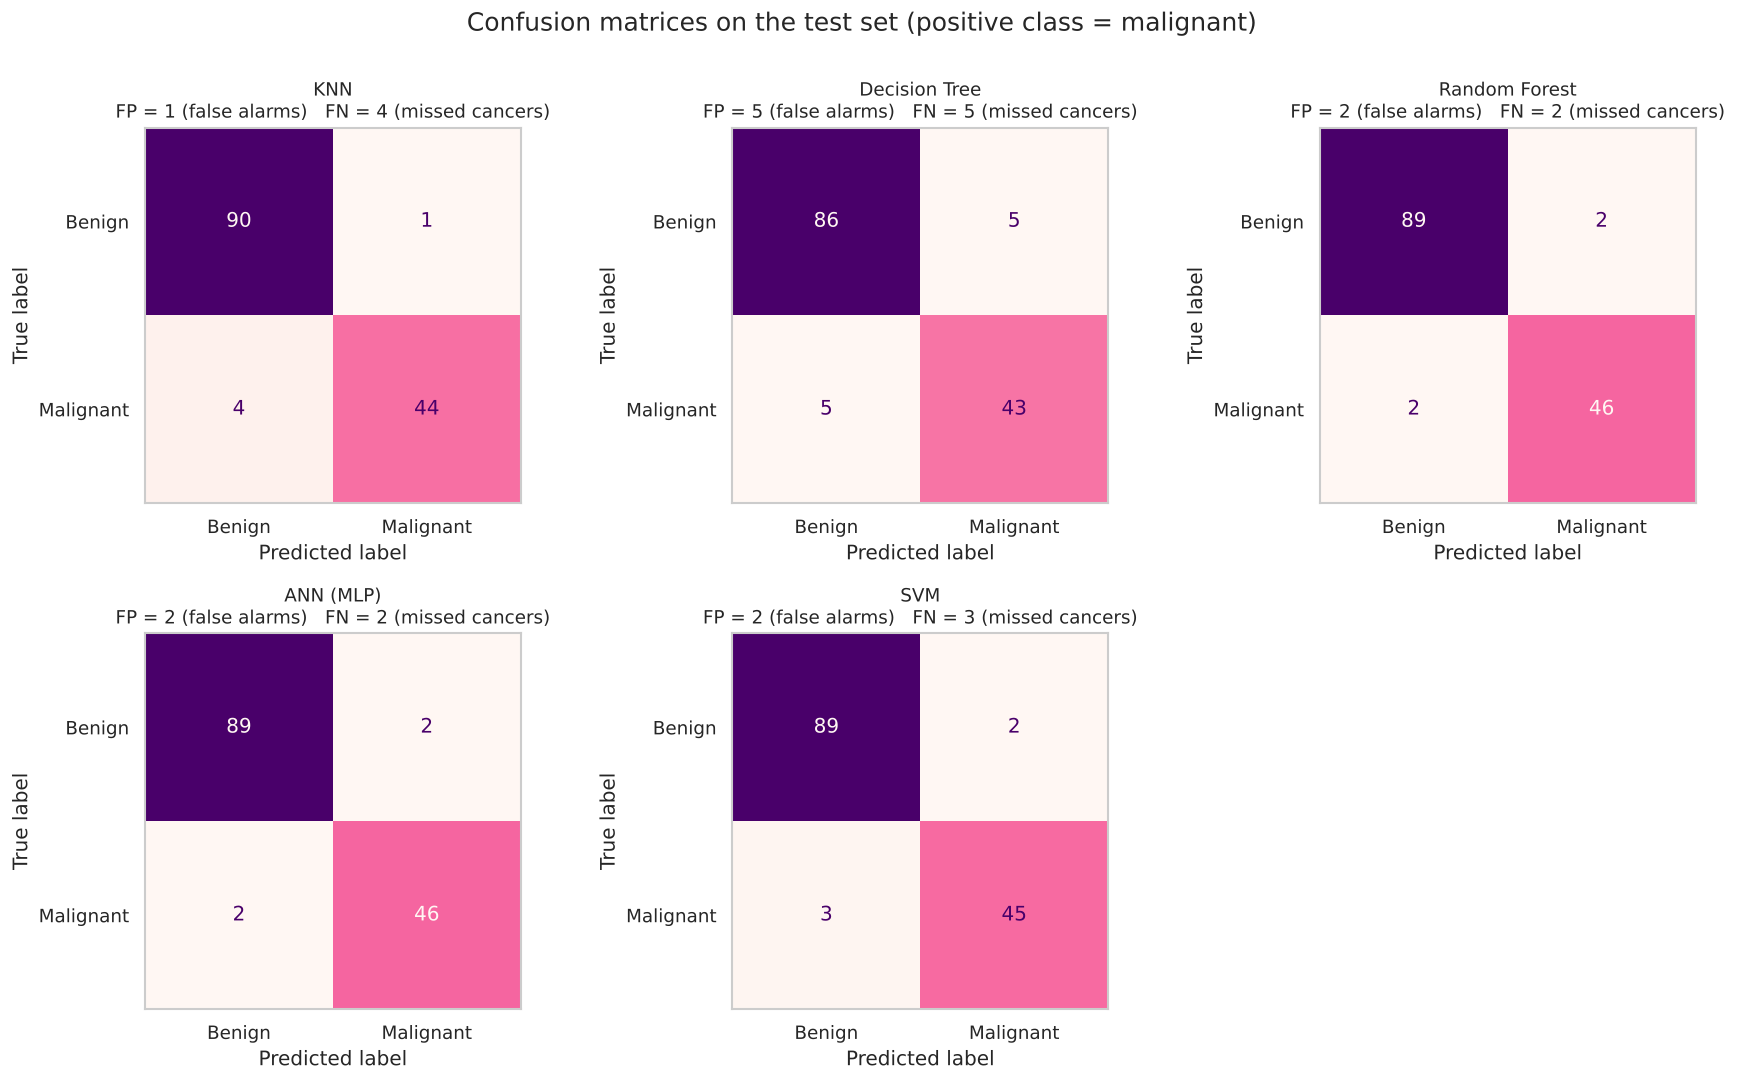

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, cm) in zip(axes.ravel(), cms.items()):
    disp = ConfusionMatrixDisplay(cm, display_labels=['Benign', 'Malignant'])
    disp.plot(ax=ax, cmap='RdPu', colorbar=False, values_format='d')
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f'{name}\nFP = {fp} (false alarms)   FN = {fn} (missed cancers)', fontsize=11)
    ax.set_xlabel('Predicted label'); ax.set_ylabel('True label')
    ax.grid(False)
axes.ravel()[-1].axis('off')
fig.suptitle('Confusion matrices on the test set (positive class = malignant)', fontsize=15, y=1.0)
plt.tight_layout()
plt.show()

### 5.4 ROC curves and metric comparison

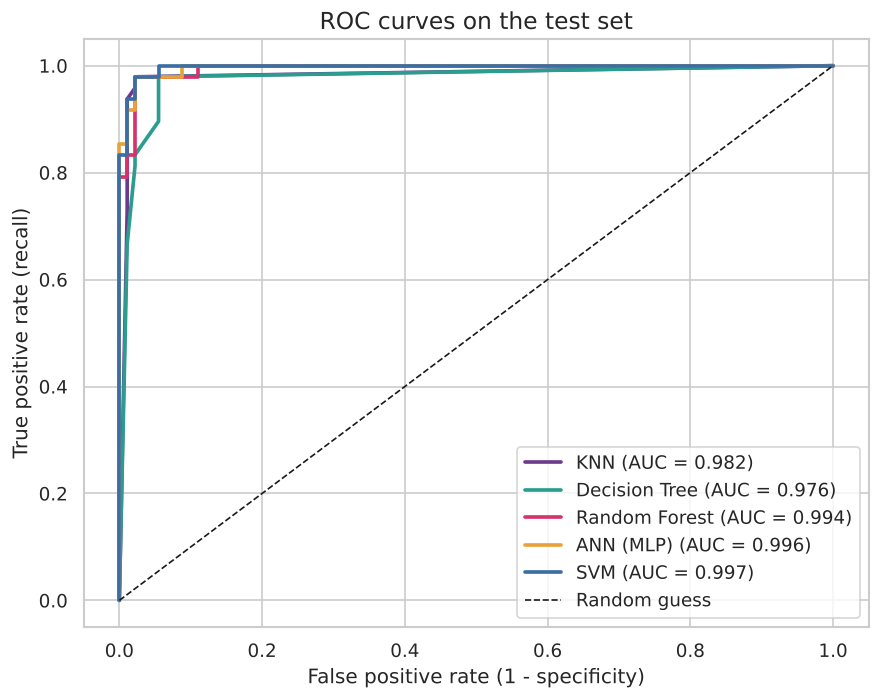

In [27]:
palette = ['#6D3B8C', '#2A9D8F', '#D6336C', '#E9A23B', '#3A6EA5']
fig, ax = plt.subplots(figsize=(7.5, 6))
for (name, s), c in zip(scores.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, lw=2.2, color=c, label=f'{name} (AUC = {roc_auc_score(y_test, s):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess')
ax.set_title('ROC curves on the test set', fontsize=14)
ax.set_xlabel('False positive rate (1 - specificity)')
ax.set_ylabel('True positive rate (recall)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

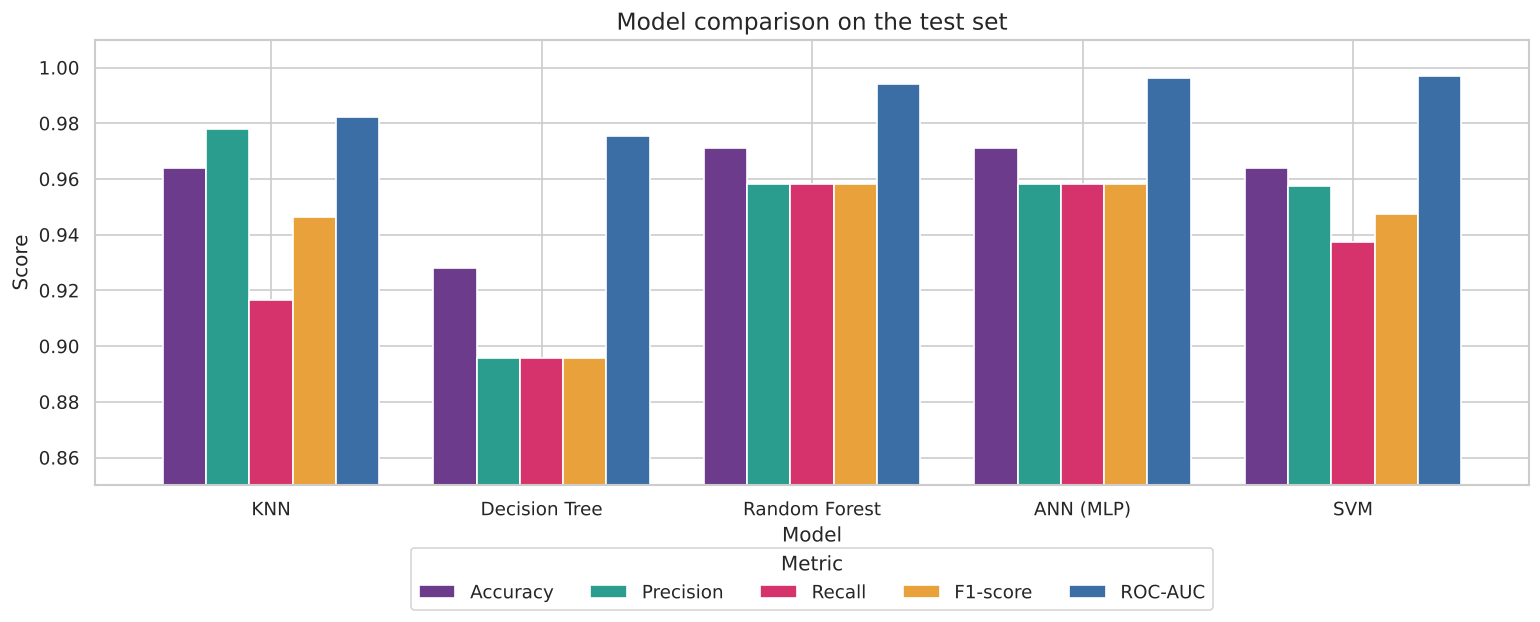

In [28]:
plot_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
ax = results[plot_metrics].plot(kind='bar', figsize=(13, 5.5), color=palette, width=0.8, edgecolor='white')
ax.set_title('Model comparison on the test set', fontsize=14)
ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_ylim(0.85, 1.01)
plt.xticks(rotation=0)
ax.legend(title='Metric', ncol=5, loc='lower center', bbox_to_anchor=(0.5, -0.3))
plt.tight_layout()
plt.show()

### 5.5 How stable are these results? (repeated cross-validation, training data only)

In [29]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
stab = []
for name, gs in searches.items():
    sc = cross_val_score(clone(gs.best_estimator_), X_train, y_train, cv=rcv, scoring='f1')
    stab.append({'Model': name, 'Repeated-CV F1 (mean)': sc.mean(), 'Std': sc.std()})
stability = pd.DataFrame(stab).set_index('Model')
display(stability.round(4))
print('Test set size:', len(y_test), '| malignant cases in test set:', int(y_test.sum()))

,Repeated-CV F1 (mean),Std
Model,,
KNN,0.9505,0.0264
Decision Tree,0.9156,0.0310
Random Forest,0.9534,0.0242
ANN (MLP),0.9567,0.0244
SVM,0.9530,0.0284


Test set size: 139 | malignant cases in test set: 48


### 5.6 Interpretation of the results

**Reading the table (test set: 139 patients, 48 malignant)**

* **Random Forest and ANN** have the best overall results and are tied on accuracy (97.1%), precision, recall and F1 (all 95.8%): each makes only 2 false alarms and misses 2 cancers. The ANN has a slightly higher ROC-AUC (0.996 vs 0.994) and the highest cross-validated F1 on the training set.
* **SVM** has the highest ROC-AUC of all (0.997), which means it ranks malignant cases above benign ones best, but at the default 0.5 threshold it misses 3 cancers (recall 93.8%).
* **KNN** has the highest precision (97.8%, only 1 false alarm) but the lowest recall among the top four (91.7%): it misses 4 cancers. In a medical screening setting, missed cancers are the more costly error, so this trade-off is less attractive.
* **Decision Tree** is clearly the weakest (accuracy 92.8%, F1 89.6%, 5 false alarms and 5 missed cancers). A single tree is unstable and has a more jagged decision boundary than the other models.

**Important caveat:** with only 48 malignant cases in the test set, one extra error changes recall by about 2 percentage points. The differences between the top four models are therefore within noise: repeated cross-validation on the training data gives F1 between 0.950 and 0.957 with a standard deviation of about 0.025 for each of them. The Decision Tree is the only model that is reliably worse (0.916).

### 5.7 Best model: selection and detailed report

In [30]:
best_name = comparison.index[0]
print('Selection rule: highest test F1-score, ties broken by recall, then ROC-AUC.')
print('Best model:', best_name)
print('Tuned hyperparameters:', {k.replace('clf__', ''): v for k, v in searches[best_name].best_params_.items()})
print()
print(classification_report(y_test, preds[best_name], target_names=['Benign', 'Malignant'], digits=3))

Selection rule: highest test F1-score, ties broken by recall, then ROC-AUC.
Best model: ANN (MLP)
Tuned hyperparameters: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (8,), 'learning_rate_init': 0.001}

              precision    recall  f1-score   support

      Benign      0.978     0.978     0.978        91
   Malignant      0.958     0.958     0.958        48

    accuracy                          0.971       139
   macro avg      0.968     0.968     0.968       139
weighted avg      0.971     0.971     0.971       139



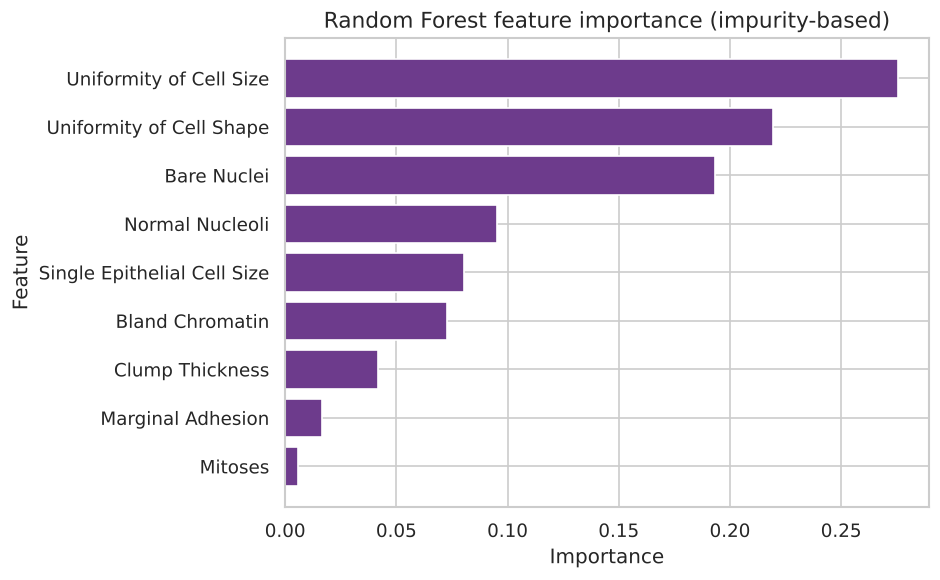

In [31]:
rf_model = searches['Random Forest'].best_estimator_
imp = pd.Series(rf_model.named_steps['clf'].feature_importances_, index=features).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index.str.replace('_', ' '), imp.values, color='#6D3B8C')
ax.set_title('Random Forest feature importance (impurity-based)', fontsize=13)
ax.set_xlabel('Importance')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

### 5.8 Sensitivity check: removing rows that repeat across different patients

In [32]:
# Variant dataset: also drop rows whose 9 features + class repeat (even with different IDs), then redo the split and refit the tuned models
raw = df.copy(); raw['Diagnosis'] = raw[target].map({2: 0, 4: 1})
strict = raw.drop(columns=[id_col, target]).drop_duplicates()
Xs, ys = strict[features], strict['Diagnosis']
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.20, stratify=ys, random_state=RANDOM_STATE)
print('Rows after strict de-duplication:', len(strict), '| train:', len(Xs_tr), '| test:', len(Xs_te))

rows = []
for name, gs in searches.items():
    m = clone(gs.best_estimator_).fit(Xs_tr, ys_tr)
    p = m.predict(Xs_te)
    rows.append({'Model': name, 'Accuracy': accuracy_score(ys_te, p), 'Recall': recall_score(ys_te, p),
                 'F1-score': f1_score(ys_te, p), 'ROC-AUC': roc_auc_score(ys_te, get_scores(m, Xs_te))})
sens = pd.DataFrame(rows).set_index('Model').round(4)
sens

Rows after strict de-duplication: 463 | train: 370 | test: 93


,Accuracy,Recall,F1-score,ROC-AUC
Model,,,,
KNN,0.9570,0.9583,0.9583,0.9583
Decision Tree,0.9140,0.9375,0.9184,0.9222
Random Forest,0.9462,0.9583,0.9485,0.9870
ANN (MLP),0.9462,0.9583,0.9485,0.9833
SVM,0.9462,0.9583,0.9485,0.9880


**Interpretation:** when rows that repeat across different patients are also removed (463 rows, 93 test samples), the picture is the same: the Decision Tree is still the weakest model, while the other four reach 94.6-95.7% accuracy. KNN edges ahead in this smaller split, which again shows that the order among the top four depends on the particular split. The decision to keep rows with identical features but different IDs does not change the conclusion that the Decision Tree is the weakest model and that the other four models perform almost equally well.

In [33]:
# Save the numbers used in the presentation
import os
os.makedirs('out', exist_ok=True)
out = {
    'results': results.round(4).reset_index().to_dict(orient='records'),
    'stability': stability.round(4).reset_index().to_dict(orient='records'),
    'sensitivity': sens.reset_index().to_dict(orient='records'),
    'confusion': {k: v.tolist() for k, v in cms.items()},
    'best_params': {k: {p.replace('clf__', ''): (list(v) if isinstance(v, tuple) else v) for p, v in gs.best_params_.items()} for k, gs in searches.items()},
    'best_name': best_name,
    'n_train': int(len(y_train)), 'n_test': int(len(y_test)),
    'test_malignant': int(y_test.sum()),
    'class_counts_raw': {'benign': 458, 'malignant': 241},
    'rf_importance': imp.sort_values(ascending=False).round(4).to_dict(),
    'corr_with_target': corr['Diagnosis (malignant=1)'].drop('Diagnosis (malignant=1)').round(3).to_dict(),
}
json.dump(out, open('out/results.json', 'w'), indent=2, default=float)
results.round(4).to_csv('out/model_comparison.csv')
print('Saved results.json and model_comparison.csv')

Saved results.json and model_comparison.csv


---
# Conclusion and Future Work

### Summary of the results
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| KNN | 0.964 | 0.978 | 0.917 | 0.946 | 0.982 |
| Decision Tree | 0.928 | 0.896 | 0.896 | 0.896 | 0.976 |
| Random Forest | 0.971 | 0.958 | 0.958 | 0.958 | 0.994 |
| **ANN (MLP)** | **0.971** | **0.958** | **0.958** | **0.958** | **0.996** |
| SVM | 0.964 | 0.957 | 0.938 | 0.947 | 0.997 |

### Best model: ANN (MLP), with Random Forest as a very close second
Using the pre-defined rule (highest test F1, ties broken by recall and then ROC-AUC), the **ANN** is selected. It ties with Random Forest on accuracy, precision, recall and F1 (97.1% / 95.8% / 95.8% / 95.8%), it has the higher ROC-AUC of the two (0.996), and it also has the best cross-validated F1 on the training data (0.956 in the grid search and 0.957 in repeated CV). It made 2 false alarms and missed 2 of 48 cancers.

**Honest caveat:** the gap between the ANN, Random Forest, SVM and KNN is small compared with the uncertainty of a 139-sample test set. The firm conclusion is that these four models are all strong (about 96-97% accuracy and ROC-AUC of 0.98 or higher), and that the single Decision Tree is the weakest. If interpretability matters more than the last fraction of a percent, Random Forest (with feature importances) is an equally good choice.

### Limitations
* Small dataset (691 unique rows after cleaning) and a single 80:20 split for the final test.
* All features are ordinal scores assigned by a pathologist, so the models depend on that human rating.
* The data was collected in 1989-1991 at one hospital; performance on other populations is unknown.
* The decision threshold was left at the default 0.5.

### Possible future improvements
* Use repeated or nested cross-validation for the final comparison to reduce the dependence on one split.
* Tune the decision threshold (or use class weights) to push recall higher, since a missed cancer is worse than a false alarm.
* Calibrate the predicted probabilities and add model explanations (SHAP / permutation importance).
* Try gradient boosting (XGBoost / LightGBM) and ensembles of the best models.
* Validate on external data such as the WDBC (digitized image) dataset or data from other hospitals.

*Important: this is a student machine-learning exercise, not a medical device; it must not be used for real diagnosis.*